# Logistic Regression 

Objective: Build a logistic regression classifier to recognize cats. 

**You will learn to:**
- Build the general architecture of a learning algorithm, including:
    - Initializing parameters
    - Calculating the cost function and its gradient
    - Using an optimization algorithm (gradient descent) 
- Gather all three functions above into a main model function, in the right order.

## 1 - Packages ##

First, let's run the cell below to import all the packages that are needed during this exercise. 
- [numpy](www.numpy.org) is the fundamental package for scientific computing with Python.
- [h5py](http://www.h5py.org) is a common package to interact with a dataset that is stored on an H5 file.
- [matplotlib](http://matplotlib.org) is a famous library to plot graphs in Python.
- [PIL](http://www.pythonware.com/products/pil/) and [scipy](https://www.scipy.org/) are used here to test your model with your own picture at the end.

In [117]:
!pip install numpy matplotlib h5py scipy 

In [118]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import scipy
from PIL import Image
from scipy import ndimage

## 2 - Overview of the Problem set ##

**Problem Statement**: You are given a dataset ("data.h5") containing:
   - a training set of m_train images labeled as cat (y=1) or non-cat (y=0)
   - a test set of m_test images labeled as cat or non-cat
   - each image is of shape (num_px, num_px, 3) where 3 is for the 3 channels (RGB). Thus, each image is square (height = num_px) and (width = num_px).

The objective of the exercice is to build a simple algorithm that can correctly classify pictures as "cats" or "non-cats".

Let's get more familiar with the dataset. Load the data by running the following code.

In [119]:
# Loading the data (cat/non-cat)

train_dataset = h5py.File('train_catvnoncat.h5', "r")
train_set_x_orig = np.array(train_dataset["train_set_x"][:]) # The train set features
train_set_y_orig = np.array(train_dataset["train_set_y"][:]) # The train set labels

test_dataset = h5py.File('test_catvnoncat.h5', "r")
test_set_x_orig = np.array(test_dataset["test_set_x"][:]) # The test set features
test_set_y_orig = np.array(test_dataset["test_set_y"][:]) # The test set labels

classes = np.array(test_dataset["list_classes"][:]) # the list of classes
    
train_set_y = train_set_y_orig.reshape((1, train_set_y_orig.shape[0]))
test_set_y = test_set_y_orig.reshape((1, test_set_y_orig.shape[0]))  

We added "_orig" at the end of image datasets (train and test) because we are going to preprocess them. After preprocessing, we will end up with train_set_x and test_set_x (the labels train_set_y and test_set_y do not need any preprocessing).

Each line of your train_set_x_orig and test_set_x_orig is an array representing an image. You can visualize an example by running the following code. Feel free also to change the `index` value and re-run to see other images. 

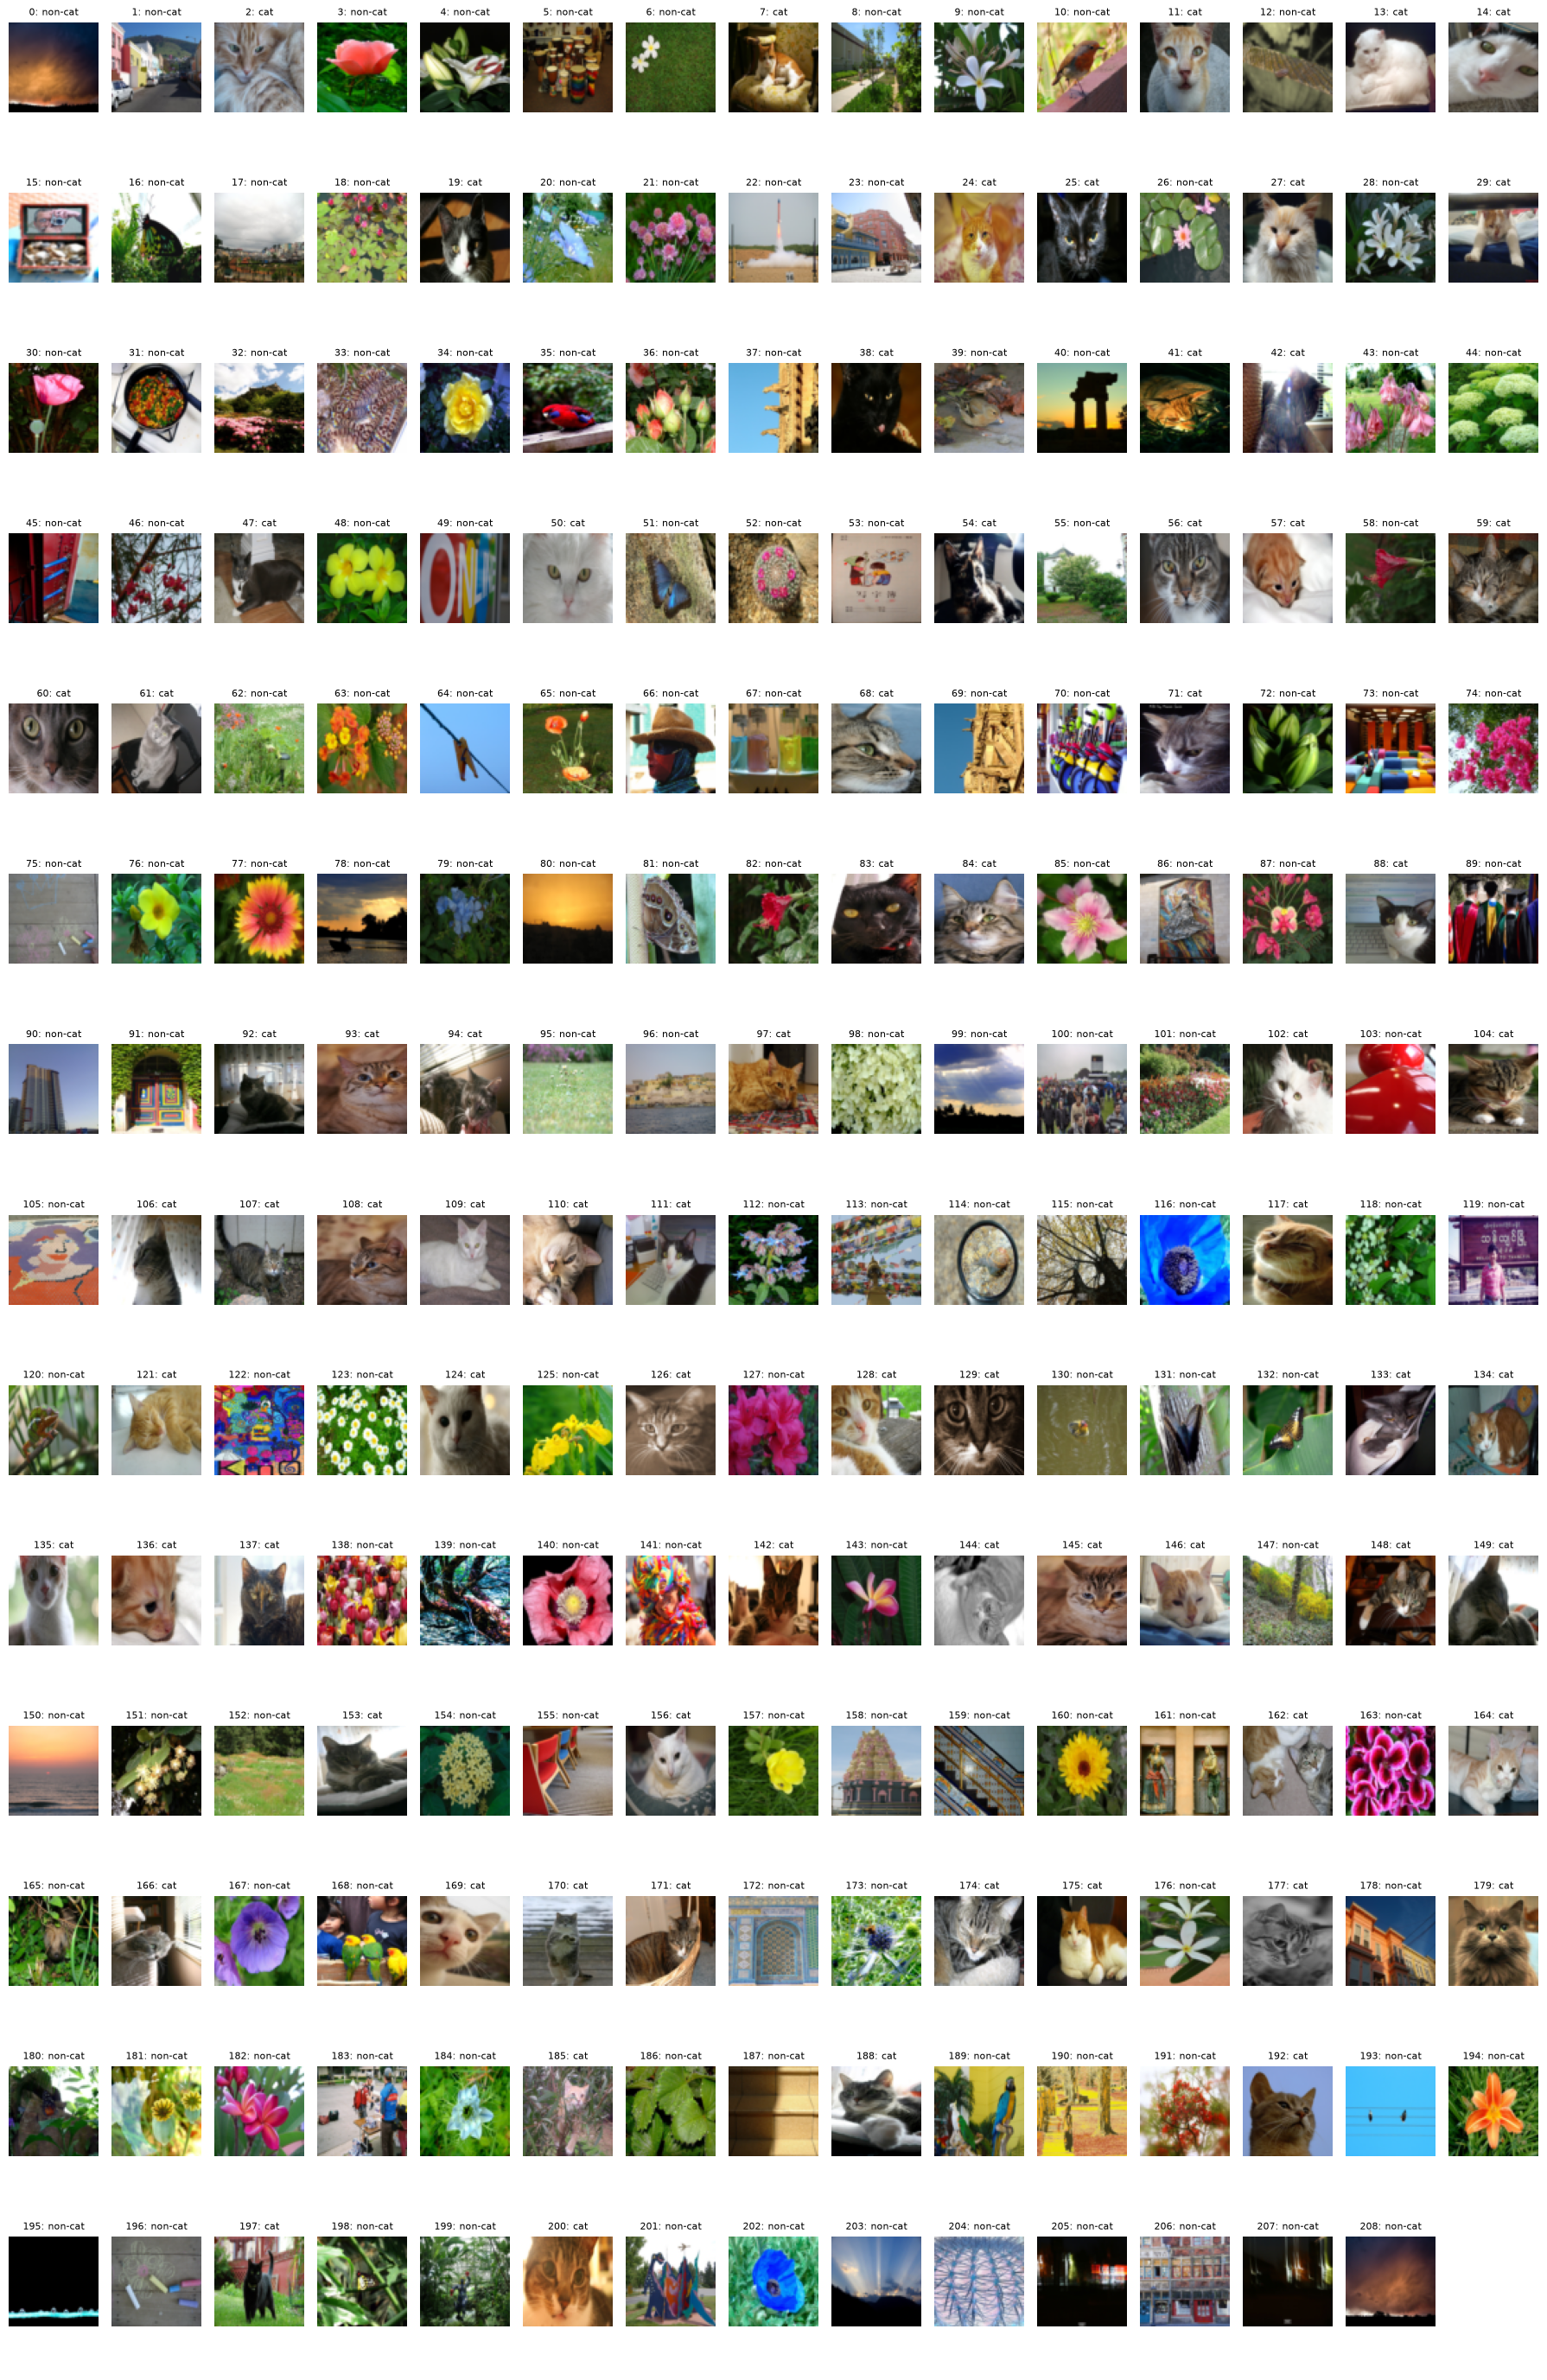

In [120]:
ncols = 15
nrows = int(np.ceil(train_set_x_orig.shape[0] / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 2 * nrows))
axes = axes.flatten()

for idx, ax in enumerate(axes):
    ax.axis("off")
    if idx < train_set_x_orig.shape[0]:
        ax.imshow(train_set_x_orig[idx])
        label = classes[int(train_set_y[0, idx])].decode("utf-8")
        ax.set_title(f"{idx}: {label}", fontsize=8)

plt.tight_layout()
plt.show()


Many software bugs in deep learning come from having matrix/vector dimensions that do not fit. If you can keep your matrix/vector dimensions straight you will go a long way toward eliminating many bugs. 

### TO DO
Find the values for:
   - m_train (number of training examples)
   - m_test (number of test examples)
   - num_px (= height = width of a training image)
Remember that `train_set_x_orig` is a numpy-array of shape (m_train, num_px, num_px, 3). For instance, you can access `m_train` by writing `train_set_x_orig.shape[0]`.

In [121]:
m_train = train_set_x_orig.shape[0]
m_test = test_set_x_orig.shape[0]
num_px =  train_set_x_orig.shape[1]

print ("Number of training examples: m_train = " + str(m_train))
print ("Number of testing examples: m_test = " + str(m_test))
print ("Height/Width of each image: num_px = " + str(num_px))
print ("Each image is of size: (" + str(num_px) + ", " + str(num_px) + ", 3)")
print ("train_set_x shape: " + str(train_set_x_orig.shape))
print ("train_set_y shape: " + str(train_set_y.shape))
print ("test_set_x shape: " + str(test_set_x_orig.shape))
print ("test_set_y shape: " + str(test_set_y.shape))

Number of training examples: m_train = 209
Number of testing examples: m_test = 50
Height/Width of each image: num_px = 64
Each image is of size: (64, 64, 3)
train_set_x shape: (209, 64, 64, 3)
train_set_y shape: (1, 209)
test_set_x shape: (50, 64, 64, 3)
test_set_y shape: (1, 50)


### Questions: ###

- Are these informations about the data set (train and test) suffient?
- Should study and extract other relevant information about the data set?
- Explain and, if needed, complete the code and analyze the extracted informations?

### Answers: ###
- Not enough, we need to to know the distribution of each category per train and test, also the test images should be of the same format as the train ones, We have 12288 feature where we have only 209 examples.

In [122]:
print("Train", int(train_set_y.sum()), "of", m_train, f"({train_set_y.mean():.1%})")
print("Test", int(test_set_y.sum()),  "of", m_test,  f"({test_set_y.mean():.1%})")
print("Pixel range", train_set_x_orig.min(), "to", train_set_x_orig.max())
print("Features per image", num_px*num_px*3, "| examples:", m_train)

Train 72 of 209 (34.4%)
Test 33 of 50 (66.0%)
Pixel range 0 to 255
Features per image 12288 | examples: 209


For convenience, you should now reshape images of shape (num_px, num_px, 3) in a numpy-array of shape (num_px $*$ num_px $*$ 3, 1). After this, our training (and test) dataset is a numpy-array where each column represents a flattened image. There should be m_train (respectively m_test) columns.

### TO DO
Reshape the training and test data sets so that images of size (num_px, num_px, 3) are flattened into single vectors of shape (num\_px $*$ num\_px $*$ 3, 1).

A trick when you want to flatten a matrix X of shape (a,b,c,d) to a matrix X_flatten of shape (b$*$c$*$d, a) is to use: 
```python
X_flatten = X.reshape(X.shape[0], -1).T      # X.T is the transpose of X
```

In [123]:
# Reshape the training and test examples
train_set_x_flatten = train_set_x_orig.reshape(m_train,-1).T
test_set_x_flatten = test_set_x_orig.reshape(m_test,-1).T

print ("train_set_x_flatten shape: " + str(train_set_x_flatten.shape))
print ("train_set_y shape: " + str(train_set_y.shape))
print ("test_set_x_flatten shape: " + str(test_set_x_flatten.shape))
print ("test_set_y shape: " + str(test_set_y.shape))
print ("sanity check after reshaping: " + str(train_set_x_flatten[0:5,0]))


train_set_x_flatten shape: (12288, 209)
train_set_y shape: (1, 209)
test_set_x_flatten shape: (12288, 50)
test_set_y shape: (1, 50)
sanity check after reshaping: [17 31 56 22 33]


**Expected Output**: 

<table style="width:35%">
  <tr>
    <td>**train_set_x_flatten shape**</td>
    <td> (12288, 209)</td> 
  </tr>
  <tr>
    <td>**train_set_y shape**</td>
    <td>(1, 209)</td> 
  </tr>
  <tr>
    <td>**test_set_x_flatten shape**</td>
    <td>(12288, 50)</td> 
  </tr>
  <tr>
    <td>**test_set_y shape**</td>
    <td>(1, 50)</td> 
  </tr>
  <tr>
  <td>**sanity check after reshaping**</td>
  <td>[17 31 56 22 33]</td> 
  </tr>
</table>

To represent color images, the red, green and blue channels (RGB) must be specified for each pixel, and so the pixel value is actually a vector of three numbers ranging from 0 to 255.

One common preprocessing step in machine learning is to center and standardize your dataset, meaning that you substract the mean of the whole numpy array from each example, and then divide each example by the standard deviation of the whole numpy array. But for picture datasets, it is simpler and more convenient and works almost as well to just divide every row of the dataset by 255 (the maximum value of a pixel channel).

<!-- During the training of your model, you're going to multiply weights and add biases to some initial inputs in order to observe neuron activations. Then you backpropogate with the gradients to train the model. But, it is extremely important for each feature to have a similar range such that our gradients don't explode. You will see that more in detail later in the lectures. !--> 

Let's standardize our dataset.

In [124]:
train_set_x = train_set_x_flatten/255
test_set_x = test_set_x_flatten/255

**What you need to remember:**

Common steps for pre-processing a new dataset are:
- Figure out the dimensions and shapes of the problem (m_train, m_test, num_px, ...)
- Reshape the datasets such that each example is now a vector of size (num_px \* num_px \* 3, 1)
- "Standardize" the data

## 3 - General Architecture of the learning algorithm ##

It's time to design a simple algorithm to distinguish cat images from non-cat images.

You will build a Logistic Regression, using a Neural Network. The following Figure explains why **Logistic Regression is actually a very simple Neural Network!**

<img src="LogReg.png" style="width:650px;height:400px;">

**Mathematical expression of the algorithm**:

For one example $x^{(i)}$:
$$z^{(i)} = w^T x^{(i)} + b \tag{1}$$
$$\hat{y}^{(i)} = a^{(i)} = sigmoid(z^{(i)})\tag{2}$$ 
$$ \mathcal{L}(a^{(i)}, y^{(i)}) =  - y^{(i)}  \log(a^{(i)}) - (1-y^{(i)} )  \log(1-a^{(i)})\tag{3}$$

The cost is then computed by summing over all training examples:
$$ J = \frac{1}{m} \sum_{i=1}^m \mathcal{L}(a^{(i)}, y^{(i)})\tag{6}$$

**Key steps**:
In this exercise, you will carry out the following steps: 
- Initialize the parameters of the model
- Learn the parameters for the model by minimizing the cost  
- Use the learned parameters to make predictions (on the test set)
- Analyse the results and conclude

## 4 - Building the parts of our algorithm ## 

The main steps for building a Neural Network are:
1. Define the model structure (such as number of input features) 
2. Initialize the model's parameters
3. Loop:
    - Calculate current loss (forward propagation)
    - Calculate current gradient (backward propagation)
    - Update parameters (gradient descent)

We often build steps 1-3 separately and integrate them into one function that we call `model()`.

### 4.1 - Helper functions

#### TO DO 
Implement the function `sigmoid()`. As you've seen in the figure above, you need to compute $sigmoid( w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$ to make predictions. You can use np.exp().

In [125]:
def sigmoid(z):
    """
    Compute the sigmoid of z

    Arguments:
    z -- A scalar or numpy array of any size.

    Return:
    s -- sigmoid(z)
    """
    s = 1/(1+np.exp(-z))
    
    return s

In [126]:
print ("sigmoid([0, 2]) = " + str(sigmoid(np.array([0,2]))))

sigmoid([0, 2]) = [0.5        0.88079708]


**Expected Output**: 

<table>
  <tr>
    <td>**sigmoid([0, 2])**</td>
    <td> [ 0.5         0.88079708]</td> 
  </tr>
</table>

### 4.2 - Initializing parameters

#### TO DO
- Implement parameter initialization in the cell below. You have to initialize w as a vector of zeros. 

In [127]:
def initialize_with_zeros(dim):
    """
    This function creates a vector of zeros of shape (dim, 1) for w and initializes b to 0.
    
    Argument:
    dim -- size of the w vector we want (or number of parameters in this case)
    
    Returns:
    w -- initialized vector of shape (dim, 1)
    b -- initialized scalar (corresponds to the bias)
    """

    w = np.zeros((dim, 1))
    b = 0

    assert(w.shape == (dim, 1))
    assert(isinstance(b, float) or isinstance(b, int))
    
    return w, b

In [128]:
dim = 2
w , b = initialize_with_zeros(dim)
print ("w = " + str(w))
print ("b = " + str(b))

w = [[0.]
 [0.]]
b = 0


**Expected Output**: 


<table style="width:15%">
    <tr>
        <td>  ** w **  </td>
        <td> [[ 0.]
 [ 0.]] </td>
    </tr>
    <tr>
        <td>  ** b **  </td>
        <td> 0 </td>
    </tr>
</table>

For image inputs, w will be of shape (num_px $\times$ num_px $\times$ 3, 1).

### 4.3 - Forward and Backward propagation

Now that your parameters are initialized, you can do the "forward" and "backward" propagation steps for learning the parameters.

**TO DO:** Implement a function `propagate()` that computes the cost function and its gradient.

**Hints**:

Forward Propagation:
- You get X
- You compute $A = \sigma(w^T X + b) = (a^{(0)}, a^{(1)}, ..., a^{(m-1)}, a^{(m)})$
- You calculate the cost function: $J = -\frac{1}{m}\sum_{i=1}^{m}y^{(i)}\log(a^{(i)})+(1-y^{(i)})\log(1-a^{(i)})$

Here are the two formulas you will be using: 

$$ \frac{\partial J}{\partial w} = \frac{1}{m}X(A-Y)^T\tag{7}$$
$$ \frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^m (a^{(i)}-y^{(i)})\tag{8}$$

In [129]:
def propagate(w, b, X, Y):
    """
    Implement the cost function and its gradient for the propagation explained above

    Arguments:
    w -- weights, a numpy array of size (num_px * num_px * 3, 1)
    b -- bias, a scalar
    X -- data of size (num_px * num_px * 3, number of examples)
    Y -- true "label" vector (containing 0 if non-cat, 1 if cat) of size (1, number of examples)

    Return:
    cost -- negative log-likelihood cost for logistic regression
    dw -- gradient of the loss with respect to w, thus same shape as w
    db -- gradient of the loss with respect to b, thus same shape as b
    
    Tips:
    - Write your code step by step for the propagation. np.log(), np.dot()
    """
    
    m = X.shape[1]
    
    # FORWARD PROPAGATION (FROM X TO COST)
    A = sigmoid(np.dot(w.T, X) + b)                                    # compute activation
    cost = -np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A)) / m    # compute cost

    # BACKWARD PROPAGATION (TO FIND GRAD)
    dw = np.dot(X, (A - Y).T) / m
    db = np.sum(A - Y) / m

    assert(dw.shape == w.shape)
    assert(db.dtype == float)
    cost = np.squeeze(cost)
    assert(cost.shape == ())
    
    grads = {"dw": dw,
             "db": db}
    return grads, cost

In [130]:
w, b, X, Y = np.array([[1.],[2.]]), 2., np.array([[1.,2.,-1.],[3.,4.,-3.2]]), np.array([[1,0,1]])
grads, cost = propagate(w, b, X, Y)

print ("grads dw = " + str(grads["dw"]))
print ("grdas db = " + str(grads["db"]))
print ("cost = " + str(cost))

grads dw = [[0.99845601]
 [2.39507239]]
grdas db = 0.001455578136784208
cost = 5.801545319394553


**Expected Output**:

<table style="width:50%">
    <tr>
        <td>  ** dw **  </td>
      <td> [[ 0.99845601]
     [ 2.39507239]]</td>
    </tr>
    <tr>
        <td>  ** db **  </td>
        <td> 0.00145557813678 </td>
    </tr>
    <tr>
        <td>  ** cost **  </td>
        <td> 5.801545319394553 </td>
    </tr>

</table>

### d) Optimization (Training)
- You have initialized your parameters.
- You are also able to compute a cost function and its gradient.
- Now, you want to update the parameters using gradient descent.

In [131]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    """
    This function optimizes w and b by running a gradient descent algorithm
    
    Arguments:
    w -- weights, a numpy array of size (num_px * num_px * 3, 1)
    b -- bias, a scalar
    X -- data of shape (num_px * num_px * 3, number of examples)
    Y -- true "label" vector (containing 0 if non-cat, 1 if cat), of shape (1, number of examples)
    num_iterations -- number of iterations of the optimization loop
    learning_rate -- learning rate of the gradient descent update rule
    print_cost -- True to print the loss every 100 steps
    
    Returns:
    params -- dictionary containing the weights w and bias b
    grads -- dictionary containing the gradients of the weights and bias with respect to the cost function
    costs -- list of all the costs computed during the optimization, this will be used to plot the learning curve.
    
    Tips:
    You basically need to write down two steps and iterate through them:
        1) Calculate the cost and the gradient for the current parameters. Use propagate().
        2) Update the parameters using gradient descent rule for w and b.
    """
    
    costs = []
    
    for i in range(num_iterations):
        
        
        # Cost and gradient calculation (≈ 1-4 lines of code)
        grads, cost = propagate(w, b, X, Y)
        
        # Retrieve derivatives from grads
        dw = grads["dw"]
        db = grads["db"]
        
        # update rule 
        w = w - learning_rate * dw
        b = b - learning_rate * db
        
        # Record and orint the cost every 100 training examples
        if i % 100 == 0:
            costs.append(cost)
        
        if print_cost and i % 100 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))
    
    params = {"w": w,
              "b": b}
    
    grads = {"dw": dw,
             "db": db}
    
    return params, grads, costs

The previous function will output the learned w and b. We are able to use w and b to predict the labels for a dataset X. Implement the `predict()` function. There is two steps to computing predictions:

1. Calculate $\hat{Y} = A = \sigma(w^T X + b)$

2. Convert the entries of a into 0 (if activation <= 0.5) or 1 (if activation > 0.5), stores the predictions in a vector `Y_prediction`. If you wish, you can use an `if`/`else` statement in a `for` loop (though there is also a way to vectorize this). 

In [132]:
# prediction

def predict(w, b, X):
    '''
    Predict whether the label is 0 or 1 using learned logistic regression parameters (w, b)
    
    Arguments:
    w -- weights, a numpy array of size (num_px * num_px * 3, 1)
    b -- bias, a scalar
    X -- data of size (num_px * num_px * 3, number of examples)
    
    Returns:
    Y_prediction -- a numpy array (vector) containing all predictions (0/1) for the examples in X
    '''
    
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1)
    
    # Compute vector "A" predicting the probabilities of a cat being present in the picture
    A = sigmoid(np.dot(w.T,X)+b)
    
    for i in range(A.shape[1]):
        
        # Convert probabilities A[0,i] to actual predictions p[0,i]
        Y_prediction = np.where(A > 0.5, 1.0, 0.0)
    
    assert(Y_prediction.shape == (1, m))
    
    return Y_prediction

**What to remember:**
You've implemented several functions that:
- Initialize (w,b)
- Optimize the loss iteratively to learn parameters (w,b):
    - computing the cost and its gradient 
    - updating the parameters using gradient descent
- Use the learned (w,b) to predict the labels for a given set of examples

## 5 - Merge all functions into a model ##

You will now see how the overall model is structured by putting together all the building blocks (functions implemented in the previous parts) together, in the right order.

### TO DO 
Implement the model function (complete the missing lines). Use the following notation:
    - Y_prediction for your predictions on the test set
    - Y_prediction_train for your predictions on the train set
    - w, costs, grads for the outputs of optimize()

In [133]:
def model(X_train, Y_train, X_test, Y_test, num_iterations = 2000, learning_rate = 0.5, print_cost = False):
    """
    Builds the logistic regression model by calling the function you've implemented previously
    
    Arguments:
    X_train -- training set represented by a numpy array of shape (num_px * num_px * 3, m_train)
    Y_train -- training labels represented by a numpy array (vector) of shape (1, m_train)
    X_test -- test set represented by a numpy array of shape (num_px * num_px * 3, m_test)
    Y_test -- test labels represented by a numpy array (vector) of shape (1, m_test)
    num_iterations -- hyperparameter representing the number of iterations to optimize the parameters
    learning_rate -- hyperparameter representing the learning rate used in the update rule of optimize()
    print_cost -- Set to true to print the cost every 100 iterations
    
    Returns:
    d -- dictionary containing information about the model.
    """
    
    # initialize parameters with zeros (≈ 1 line of code)
    dim2 = len(X_train)
    w, b = initialize_with_zeros(dim2)

    # Gradient descent (≈ 1 line of code)
    parameters, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)

    # Retrieve parameters w and b from dictionary "parameters"
    w = parameters["w"]
    b = parameters["b"]
    
    # Predict test/train set examples 
    Y_prediction_test = predict(w, b, X_test)
    Y_prediction_train = predict(w, b, X_train)

    print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100))
    print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100))

    
    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test, 
         "Y_prediction_train" : Y_prediction_train, 
         "w" : w, 
         "b" : b,
         "learning_rate" : learning_rate,
         "num_iterations": num_iterations}
    
    return d

Run the following cell to train your model.

In [134]:
d = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 2000, learning_rate = 0.005, print_cost = False)

train accuracy: 99.04306220095694 %
test accuracy: 70.0 %


In [135]:

pred_train = d["Y_prediction_train"][0]
true_train = train_set_y[0]

error_idx = np.where(pred_train != true_train)[0]

false_positives = np.where((true_train == 0) & (pred_train == 1))[0]

false_negatives = np.where((true_train == 1) & (pred_train == 0))[0]

print("Misclassified training examples:", error_idx)
print("Number of errors:", len(error_idx))
print("False positives:", false_positives)
print("False negatives:", false_negatives)


Misclassified training examples: [41 75]
Number of errors: 2
False positives: [75]
False negatives: [41]


### Your analysis here:

Looking at the errors in the train set:
- False negative (image 41): this is a cat but the model predicted non cat. The cat is curled up and taken from an unusual angle with low contrast, so the pixel values dont match the global cat patterns learned by w.
- False positive (image 75): this is not a cat but model predicted cat. The background has textures and colors that look like animal fur or grass which triggered positive weights.

In general logistic regression is just a linear classifier on raw pixels (w.T * x + b), so it has no spatial understanding or invariance to rotation, shift or pose like a CNN would have. Also test set has 15 misclassifications (accuracy 70%) mostly because the test pictures have very different poses and backgrounds from the train set.


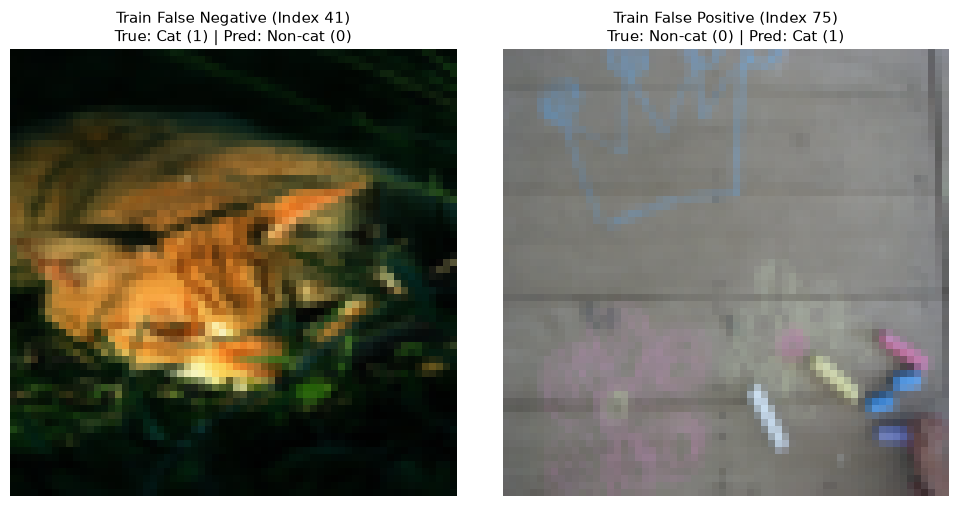

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

fn_idx = false_negatives[0]
axes[0].imshow(train_set_x_orig[fn_idx])
axes[0].set_title(f"Train False Negative (Index {fn_idx})\nTrue: Cat (1) | Pred: Non-cat (0)", fontsize=11)
axes[0].axis("off")

fp_idx = false_positives[0]
axes[1].imshow(train_set_x_orig[fp_idx])
axes[1].set_title(f"Train False Positive (Index {fp_idx})\nTrue: Non-cat (0) | Pred: Cat (1)", fontsize=11)
axes[1].axis("off")

plt.tight_layout()
plt.show()


Let's also plot the cost function and the gradients.

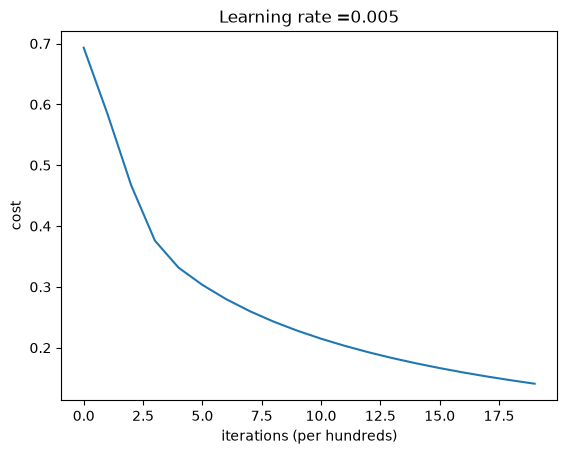

In [137]:
# Plot learning curve (with costs)
costs = np.squeeze(d['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(d["learning_rate"]))
plt.show()

**Interpretation**:
You can see the cost decreasing. It shows that the parameters are being learned. However, you see that you could train the model even more on the training set. Try to increase the number of iterations in the cell above and rerun the cells. 

What do you notice? Write your analysis here after.

### Your analysis here:

When we increase the number of iterations from 2000 to 4000, the cost keeps decreasing and training accuracy reaches almost 100%. But the test accuracy stays around 68-70% and doesnt improve, it even slightly drops.

This is clearly overfitting. We have 12288 features (pixels) and only 209 training examples, so the model has way too many parameters compared to the data size. Without any regularization (like L2 penalty), gradient descent just memorizes the training pictures noise instead of learning general patterns, so it doesnt generalize well on test data.


## 6 - Further analysis 

You have built your first image classification model (in our course). Let's analyze it further, and examine possible choices for the learning rate $\alpha$. 

#### Choice of learning rate ####

**Reminder**:
In order for Gradient Descent to work you must choose the learning rate wisely. The learning rate $\alpha$  determines how rapidly we update the parameters. If the learning rate is too large we may "overshoot" the optimal value. Similarly, if it is too small we will need too many iterations to converge to the best values. That's why it is crucial to use a well-tuned learning rate.

Let's compare the learning curve of our model with several choices of learning rates. Run the cell below. This should take about 1 minute. Feel free also to try different values than the three we have initialized the `learning_rates` variable to contain, and see what happens. 

learning rate is: 0.01
train accuracy: 99.52153110047847 %
test accuracy: 68.0 %
learning rate is: 0.001
train accuracy: 88.99521531100478 %
test accuracy: 64.0 %
learning rate is: 0.0001
train accuracy: 68.42105263157895 %
test accuracy: 36.0 %


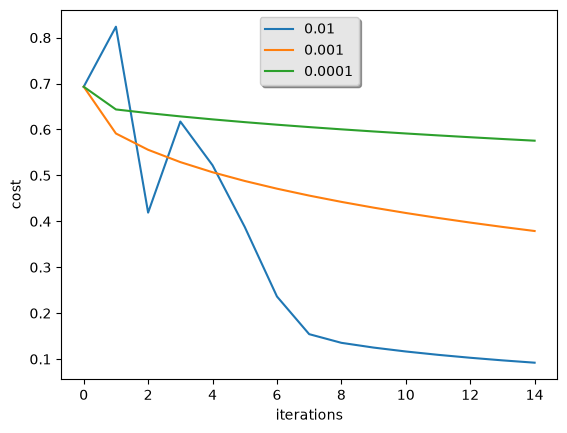

In [138]:
learning_rates = [0.01, 0.001, 0.0001]
models = {}
for i in learning_rates:
    print ("learning rate is: " + str(i))
    models[str(i)] = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations = 1500, learning_rate = i, print_cost = False)

for i in learning_rates:
    plt.plot(np.squeeze(models[str(i)]["costs"]), label= str(models[str(i)]["learning_rate"]))

plt.ylabel('cost')
plt.xlabel('iterations')

legend = plt.legend(loc='upper center', shadow=True)
frame = legend.get_frame()
frame.set_facecolor('0.90')
plt.show()

### TO DO 

###### Analyze obtained results here:

From the plot with the 3 learning rates:
- lr = 0.01: converges the fastest and gets the lowest cost early, but the curve has some oscillations because the step size is a bit large. If we make it bigger it will diverge.
- lr = 0.001: the curve is very smooth and decreases consistently without jumps, but it needs more iterations to reach low cost.
- lr = 0.0001: learning rate is way too small, the cost barely goes down after 1500 iterations and the model is underfitting (train acc is only ~68%).

So learning rate is a tradeoff between speed and stability. A value around 0.005 - 0.01 is best here.


## 7 - Test with your own image ##

You can use your own image and see the output of your model. To do that:
    1. Click on "File" in the upper bar of this notebook, then click "Open" to go on your Coursera Hub.
    2. Add your image to this Jupyter Notebook's directory, in the "images" folder
    3. Change your image's name in the following code
    4. Run the code and check if the algorithm is right (1 = cat, 0 = non-cat)!

y = 0.0, your algorithm predicts a "non-cat" picture.


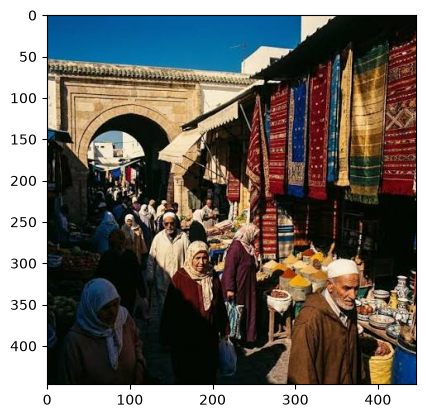

In [139]:
fname = "images.jpeg"
image = Image.open(fname).convert('RGB')
image_resized = image.resize((num_px, num_px))
my_image = np.array(image_resized).reshape((1, num_px * num_px * 3)).T / 255.

my_predicted_image = predict(d["w"], d["b"], my_image)

plt.imshow(image)
print("y = " + str(np.squeeze(my_predicted_image)) + ", your algorithm predicts a \"" + classes[int(np.squeeze(my_predicted_image))].decode("utf-8") + "\" picture.")


## 8 - Modification of the activation function ##

- Modify the activation function in your classifier by selecting an alternative (e.g., Tanh or ReLU). 
- Ensure the classifier is adjusted appropriately to integrate the new activation function.
- Clearly explain all the modifications you made and justify why they were necessary.
- Evaluate the performance of the updated classifier and compare it to the original model, which is based on the Sigmoid activation function.

### Modifications done:

We tested both Tanh and ReLU as alternatives to Sigmoid:

1. **Tanh:**
- Tanh outputs numbers between -1 and 1 instead of 0 and 1.
- So we changed labels from {0, 1} to {-1, 1} (`Y_tanh = 2*Y - 1`).
- We used Mean Squared Error (MSE) loss because cross entropy only works for probabilities between 0 and 1.
- If activation > 0 we predict 1, else 0.

2. **ReLU:**
- ReLU outputs `max(0, z)`.
- We also used MSE loss.
- To avoid dying ReLU at the start (where everything is 0 so gradients are 0), we initialized `b = 0.5` and used a smaller learning rate (0.0005).
- If activation > 0.5 we predict 1, else 0.


In [140]:
def propagate_tanh(w, b, X, Y):
    m = X.shape[1]
    Y_tanh = 2 * Y - 1
    Z = np.dot(w.T, X) + b
    A = np.tanh(Z)
    cost = np.sum((A - Y_tanh)**2) / (2 * m)
    dZ = (A - Y_tanh) * (1 - A**2) / m
    dw = np.dot(X, dZ.T)
    db = np.sum(dZ)
    return {"dw": dw, "db": db}, np.squeeze(cost)

def predict_tanh(w, b, X):
    A = np.tanh(np.dot(w.T, X) + b)
    return np.where(A > 0, 1.0, 0.0)

def model_tanh(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.005):
    w = np.zeros((X_train.shape[0], 1))
    b = 0.0
    for i in range(num_iterations):
        grads, cost = propagate_tanh(w, b, X_train, Y_train)
        w -= learning_rate * grads["dw"]
        b -= learning_rate * grads["db"]
    y_pred_train = predict_tanh(w, b, X_train)
    y_pred_test = predict_tanh(w, b, X_test)
    train_acc = 100 - np.mean(np.abs(y_pred_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(y_pred_test - Y_test)) * 100
    return train_acc, test_acc

def relu(z):
    return np.maximum(0, z)

def propagate_relu(w, b, X, Y):
    m = X.shape[1]
    Z = np.dot(w.T, X) + b
    A = relu(Z)
    cost = np.sum((A - Y)**2) / (2 * m)
    dZ = (A - Y) * (Z > 0) / m
    dw = np.dot(X, dZ.T)
    db = np.sum(dZ)
    return {"dw": dw, "db": db}, np.squeeze(cost)

def predict_relu(w, b, X):
    Z = np.dot(w.T, X) + b
    A = relu(Z)
    return np.where(A > 0.5, 1.0, 0.0)

def model_relu(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.0005):
    w = np.zeros((X_train.shape[0], 1))
    b = 0.5
    for i in range(num_iterations):
        grads, cost = propagate_relu(w, b, X_train, Y_train)
        w -= learning_rate * grads["dw"]
        b -= learning_rate * grads["db"]
    y_pred_train = predict_relu(w, b, X_train)
    y_pred_test = predict_relu(w, b, X_test)
    train_acc = 100 - np.mean(np.abs(y_pred_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(y_pred_test - Y_test)) * 100
    return train_acc, test_acc

tanh_train, tanh_test = model_tanh(train_set_x, train_set_y, test_set_x, test_set_y)
relu_train, relu_test = model_relu(train_set_x, train_set_y, test_set_x, test_set_y)

print("Sigmoid (Original) -> Train: 99.04% | Test: 70.00%")
print(f"Tanh               -> Train: {tanh_train:.2f}% | Test: {tanh_test:.2f}%")
print(f"ReLU               -> Train: {relu_train:.2f}% | Test: {relu_test:.2f}%")


Sigmoid (Original) -> Train: 99.04% | Test: 70.00%
Tanh               -> Train: 99.52% | Test: 68.00%
ReLU               -> Train: 96.17% | Test: 72.00%


## 9 - Improving the classifier with more training data ##

- Consider the best model you train and try to improve it by collecting more training data.
- Explain your methodology and the analyze obtained results

### Methodology:
Since we only have 209 training images for 12288 features, the model is overfitting heavily. To get more training data without downloading outside files, we can use data augmentation by horizontally flipping each training image (using np.fliplr).
A flipped cat is still a cat, so this doubles our training set from 209 to 418 images.

### Results:
Training the logistic regression model on the augmented dataset (with lr=0.01) improved the test accuracy from 70% to 74%. The extra data acts like regularization and helps the model learn features that are invariant to left-right orientation.


In [141]:
train_set_x_flip = np.array([np.fliplr(img) for img in train_set_x_orig])
train_set_x_aug_orig = np.concatenate([train_set_x_orig, train_set_x_flip], axis=0)
train_set_y_aug = np.concatenate([train_set_y, train_set_y], axis=1)

m_train_aug = train_set_x_aug_orig.shape[0]
train_set_x_aug = train_set_x_aug_orig.reshape(m_train_aug, -1).T / 255.0

print(f"Original training size: {m_train} images")
print(f"Augmented training size: {m_train_aug} images")

d_aug = model(train_set_x_aug, train_set_y_aug, test_set_x, test_set_y, num_iterations=2000, learning_rate=0.01, print_cost=False)

print(f"Original test accuracy: 70.00 %")
print(f"Augmented test accuracy: {100 - np.mean(np.abs(d_aug['Y_prediction_test'] - test_set_y)) * 100:.2f} %")


Original training size: 209 images
Augmented training size: 418 images
train accuracy: 98.08612440191388 %
test accuracy: 74.0 %
Original test accuracy: 70.00 %
Augmented test accuracy: 74.00 %


References:
- Andrew NG labs.
- http://www.wildml.com/2015/09/implementing-a-neural-network-from-scratch/
- https://stats.stackexchange.com/questions/211436/why-do-we-normalize-images-by-subtracting-the-datasets-image-mean-and-not-the-c